In [1]:
# STID-SI / RQ4.1 / NF-CSE-CIC-IDS2018-v2 / MULTI-CLASS
# DATA_SEED và MODEL_SEED cùng bằng seed của lần chạy.
DATA_PATH = '/kaggle/input/datasets/dhoogla/nfcsecicids2018v2/NF-CSE-CIC-IDS2018-V2.parquet'
DATA_FILENAME = 'NF-CSE-CIC-IDS2018-V2.parquet'
DATA_SEED = 45
MODEL_SEED = 45

N_SELECT = 20
BATCH_SIZE = 1024
NUM_WORKERS = 0
EPOCHS = 2                 # Giữ số epochs theo notebook MULTI gốc; thống nhất 5 seeds
LR = 3e-4
D_MODEL = 128
N_HEADS = 8
N_PERSIST = 4
SWA_WINDOW = 16
LMM_LAYERS = 4
HEAD_DROPOUT = 0.2
LMM_DROPOUT = 0.15
OUTLIER_TH = 3.0
PRE_BATCH = 50000
WARMUP_EPOCHS = 1         # EPOCHS=2 -> 1 warmup + 1 cosine (không âm T_max)
FCB_BETA = 0.9999
FCB_GAMMA = 1.5
N_APT_PHASES = None       # Sẽ lấy từ cột Attack khi đọc dữ liệu


In [2]:
import os, math, warnings, gc, random, copy, json, platform
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore', category=FutureWarning)

# Đặt trước khi thực hiện phép tính CUDA, hỗ trợ tái lập khi chạy cùng nền tảng.
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(MODEL_SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RUN_DIR = os.path.join(os.getcwd(), f'rq4_1_multiclass_ids_seed_{MODEL_SEED}')
os.makedirs(RUN_DIR, exist_ok=True)
print(f'RQ4.1 | DATA_SEED={DATA_SEED} | MODEL_SEED={MODEL_SEED} | DEVICE={DEVICE}')
print(f'Artifacts: {RUN_DIR}')


RQ4.1 | DATA_SEED=45 | MODEL_SEED=45 | DEVICE=cuda
Artifacts: /kaggle/working/rq4_1_multiclass_ids_seed_45


In [3]:
from pathlib import Path

if DATA_PATH is None:
    candidates = sorted(p for p in Path('/kaggle/input').rglob('*.parquet')
                        if p.name.casefold() == DATA_FILENAME.casefold())
    if len(candidates) != 1:
        raise FileNotFoundError(
            f'Expected one {DATA_FILENAME}, found {len(candidates)}. '
            'Attach the correct dataset and set DATA_PATH explicitly if needed.')
    DATA_PATH = str(candidates[0])
if Path(DATA_PATH).name.casefold() != DATA_FILENAME.casefold():
    raise ValueError(f'DATA_PATH must point to {DATA_FILENAME}')

df = pd.read_parquet(DATA_PATH)

# Chỉ loại FTP_COMMAND_RET_CODE như notebook gốc; giữ hai cột port.
df = df.drop(columns=['FTP_COMMAND_RET_CODE'], errors='ignore')
df = df.drop_duplicates().reset_index(drop=True)
print('Total samples after deduplication:', df.shape)

# Biến đổi đặc trưng cố định, không dùng thông tin nhãn.
if 'SRC_TO_DST_SECOND_BYTES' in df.columns:
    df['SRC_TO_DST_SECOND_BYTES_LOG'] = np.log1p(df['SRC_TO_DST_SECOND_BYTES'])
    df = df.drop(columns=['SRC_TO_DST_SECOND_BYTES'])

# RQ4.1 là MULTI-CLASS: tuyệt đối không lùi về cột Label nhị phân.
if 'Attack' not in df.columns:
    raise KeyError("RQ4.1 multi-class requires the 'Attack' column; refusing binary 'Label' fallback.")

numerical_columns = [c for c in df.columns
                     if c not in ('Label', 'Attack', 'FTP_COMMAND_RET_CODE')
                     and pd.api.types.is_numeric_dtype(df[c])]
X = df[numerical_columns].copy()
attack_raw = df['Attack'].fillna('Benign').astype(str).values
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(attack_raw).astype(np.int64)
CLASS_NAMES = list(label_encoder.classes_)
N_APT_PHASES = len(CLASS_NAMES)
if N_APT_PHASES < 3:
    raise ValueError(f'Expected multi-class labels in Attack, found {N_APT_PHASES} classes: {CLASS_NAMES}')

print(f'\nDistribution ({len(y):,} flows, {N_APT_PHASES} classes):')
for i, name in enumerate(CLASS_NAMES):
    print(f'{i:2d} - {name:30s}: {np.count_nonzero(y == i):,}')


Total samples after deduplication: (17129715, 42)

Distribution (17,129,715 flows, 15 classes):
 0 - Benign                        : 15,101,685
 1 - Bot                           : 28,033
 2 - Brute Force -Web              : 2,143
 3 - Brute Force -XSS              : 927
 4 - DDOS attack-HOIC              : 1,066,881
 5 - DDOS attack-LOIC-UDP          : 2,112
 6 - DDoS attacks-LOIC-HTTP        : 207,078
 7 - DoS attacks-GoldenEye         : 27,723
 8 - DoS attacks-Hulk              : 432,648
 9 - DoS attacks-SlowHTTPTest      : 14,116
10 - DoS attacks-Slowloris         : 9,512
11 - FTP-BruteForce                : 25,933
12 - Infilteration                 : 115,513
13 - SQL Injection                 : 432
14 - SSH-Bruteforce                : 94,979


In [4]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.feature_selection import SelectFromModel

# ---- 1. Stratified 70/10/20 split using the run seed ----
def stratified_3way_split(y, val_frac=0.10, test_frac=0.20, seed=DATA_SEED):
    rng = np.random.RandomState(seed)
    tr_idx, val_idx, te_idx = [], [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        n = len(idx)
        if n >= 3:
            n_te  = max(1, int(round(n * test_frac)))
            n_val = max(1, int(round(n * val_frac)))
            n_tr  = n - n_te - n_val
            if n_tr < 1:
                n_tr, n_val, n_te = n - 2, 1, 1
        elif n == 2:
            n_tr, n_val, n_te = 1, 0, 1
        else:
            n_tr, n_val, n_te = 1, 0, 0
        if n < 3:
            print(f'Rare class {CLASS_NAMES[c]}: Train={n_tr}, Val={n_val}, Test={n_te}')
        tr_idx.append(idx[:n_tr])
        val_idx.append(idx[n_tr:n_tr+n_val])
        te_idx.append(idx[n_tr+n_val:])
    return tuple(rng.permutation(np.concatenate(items)) for items in (tr_idx, val_idx, te_idx))

tr_i, val_i, te_i = stratified_3way_split(y, seed=DATA_SEED)
assert not (set(tr_i[:100]) & set(te_i[:100])), 'Unexpected index overlap in sampled check'
X_tr, y_tr   = X.iloc[tr_i], y[tr_i]
X_val, y_val = X.iloc[val_i], y[val_i]
X_te, y_te   = X.iloc[te_i], y[te_i]
print('Train / Val / Test shapes:', X_tr.shape, X_val.shape, X_te.shape)

# Chỉ phát hiện và loại constant columns dựa trên TRAIN (không nhìn Val/Test).
train_std = X_tr.std(numeric_only=True)
const_cols = train_std[(train_std == 0) | train_std.isna()].index.tolist()
if const_cols:
    print('Constant columns (train only):', const_cols)
    X_tr = X_tr.drop(columns=const_cols)
    X_val = X_val.drop(columns=const_cols)
    X_te = X_te.drop(columns=const_cols)
feature_names = X_tr.columns.tolist()

del X, y, df
gc.collect()

# ---- 2. Train-only statistics using the run seed ----
def robust_preprocess_large_data(X_train, X_val, X_test,
                                 batch_size=PRE_BATCH, outlier_threshold=OUTLIER_TH,
                                 data_seed=DATA_SEED):
    X_train = np.asarray(X_train, dtype=np.float32)
    X_val   = np.asarray(X_val, dtype=np.float32)
    X_test  = np.asarray(X_test, dtype=np.float32)
    rng = np.random.RandomState(data_seed)
    sample_size = min(100000, len(X_train))
    sample_indices = rng.choice(len(X_train), sample_size, replace=False)
    sample = X_train[sample_indices].copy()
    sample[~np.isfinite(sample)] = np.nan
    medians = np.nan_to_num(np.nanmedian(sample, axis=0), nan=0.0).astype(np.float32)
    stds = np.nan_to_num(np.nanstd(sample, axis=0), nan=1.0).astype(np.float32)
    stds[stds == 0] = 1.0
    del sample

    def process_batch(batch):
        batch = batch.copy()
        batch[~np.isfinite(batch)] = np.nan
        z = np.abs((batch - medians) / stds)
        bad = (z > outlier_threshold) | np.isnan(batch)
        fill = np.broadcast_to(medians, batch.shape)
        batch[bad] = fill[bad]
        return np.clip(batch, -1e6, 1e6)

    def process_all(A, label):
        chunks = [process_batch(A[s:s+batch_size]) for s in range(0, len(A), batch_size)]
        result = np.vstack(chunks)
        print(f'Processed {label}: {len(A):,} flows')
        return result

    return (process_all(X_train, 'Train'),
            process_all(X_val, 'Validation'),
            process_all(X_test, 'Test'))

X_tr_processed, X_val_processed, X_te_processed = robust_preprocess_large_data(X_tr, X_val, X_te)

# ---- 3. Extra-Trees fit on TRAIN only using the run seed ----
selector = SelectFromModel(
    ExtraTreesClassifier(n_estimators=50, random_state=DATA_SEED, n_jobs=-1),
    max_features=N_SELECT, threshold=-np.inf
)
selector.fit(X_tr_processed, y_tr)
X_tr_selected  = selector.transform(X_tr_processed)
X_val_selected = selector.transform(X_val_processed)
X_te_selected  = selector.transform(X_te_processed)
importance = selector.estimator_.feature_importances_
selected_mask = selector.get_support()
selected_features = [feature_names[i] for i in np.flatnonzero(selected_mask)]  # TRUE token order
ranked_features = [feature_names[i] for i in np.argsort(importance)[::-1] if selected_mask[i]]
assert X_tr_selected.shape[1] == N_SELECT, f'Expected {N_SELECT} selected features'
print('Top feature importance (ranked):', ranked_features)
print('Actual token order (selector.transform):', selected_features)

# ---- 4. StandardScaler fit on TRAIN only ----
scaler = StandardScaler()
tok_tr = scaler.fit_transform(X_tr_selected).astype(np.float32)
tok_val = scaler.transform(X_val_selected).astype(np.float32)
tok_te = scaler.transform(X_te_selected).astype(np.float32)
SEQ_LEN = tok_tr.shape[1]

# Record the data partition and feature selection for this run.
metadata = dict(dataset='NF-CSE-CIC-IDS2018-v2', task='multi-class',
                data_seed=DATA_SEED, model_seed=MODEL_SEED,
                train_size=int(len(y_tr)), val_size=int(len(y_val)), test_size=int(len(y_te)),
                classes=CLASS_NAMES, selected_features=selected_features,
                input_tokens=SEQ_LEN, split_fraction=[0.70, 0.10, 0.20])
with open(os.path.join(RUN_DIR, 'run_metadata.json'), 'w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)
print(f'Device: {DEVICE} | SEQ_LEN: {SEQ_LEN}')


Train / Val / Test shapes: (11990801, 40) (1712970, 40) (3425944, 40)


/usr/local/lib/python3.13/dist-packages/pandas/core/generic.py:2171: RuntimeWarning: overflow encountered in cast
  arr = np.asarray(values, dtype=dtype)


Processed Train: 11,990,801 flows
Processed Validation: 1,712,970 flows
Processed Test: 3,425,944 flows
Top feature importance (ranked): ['FLOW_DURATION_MILLISECONDS', 'TCP_WIN_MAX_IN', 'SRC_TO_DST_AVG_THROUGHPUT', 'LONGEST_FLOW_PKT', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'TCP_WIN_MAX_OUT', 'MAX_IP_PKT_LEN', 'DST_TO_SRC_AVG_THROUGHPUT', 'L4_SRC_PORT', 'MIN_IP_PKT_LEN', 'L4_DST_PORT', 'L7_PROTO', 'MAX_TTL', 'MIN_TTL', 'SHORTEST_FLOW_PKT', 'DURATION_IN', 'DNS_QUERY_ID', 'SRC_TO_DST_SECOND_BYTES_LOG', 'SERVER_TCP_FLAGS']
Actual token order (selector.transform): ['L4_SRC_PORT', 'L4_DST_PORT', 'L7_PROTO', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'DNS_QUERY_ID', 'SRC_TO_DST_SECOND_BYTES_LOG']
Device: cuda | SEQ_LEN: 20


In [5]:
class TokenDS(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).long()
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.X[i], self.y[i]

# The run seed controls model initialization, dropout and training shuffle.
seed_everything(MODEL_SEED)
train_generator = torch.Generator()
train_generator.manual_seed(MODEL_SEED)
loader_kw = dict(num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'))
train_loader = DataLoader(TokenDS(tok_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True,
                          generator=train_generator, drop_last=False, **loader_kw)
val_loader = DataLoader(TokenDS(tok_val, y_val), batch_size=BATCH_SIZE,
                        shuffle=False, **loader_kw)
test_loader = DataLoader(TokenDS(tok_te, y_te), batch_size=BATCH_SIZE,
                         shuffle=False, **loader_kw)


In [6]:
ROPE_BASE = 1000.0   

def build_rope_cache(seq_len, inv_freq, device):
    t = torch.arange(seq_len, device=device).float()
    angles = torch.outer(t, inv_freq.to(device))          
    cos = angles.cos().repeat_interleave(2, dim=-1)
    sin = angles.sin().repeat_interleave(2, dim=-1)
    return cos, sin

def apply_rope(x, cos, sin):
    cos = cos.unsqueeze(0).unsqueeze(2)   
    sin = sin.unsqueeze(0).unsqueeze(2)   
    x1 = x[..., 0::2]; x2 = x[..., 1::2]
    x_rot = torch.stack((-x2, x1), dim=-1).flatten(-2)
    return x * cos + x_rot * sin

class Adaptive_Weighting_Attention(nn.Module):
    def __init__(self, d_model, n_heads, d_head, R):
        super().__init__()
        assert R >= 1 and n_heads >= 1 and d_head >= 1
        self.R, self.h, self.dh = R, n_heads, d_head
        self.A = nn.Linear(d_model, R * n_heads, bias=False)
        self.B = nn.Linear(d_model, R * d_head,  bias=False)
        nn.init.xavier_uniform_(self.A.weight)
        nn.init.xavier_uniform_(self.B.weight)

        self.alpha = nn.Parameter(torch.ones(R, n_heads))

    def forward(self, x):                       
        B, L, _ = x.shape
        a = self.A(x).view(B, L, self.R, self.h)    
        b = self.B(x).view(B, L, self.R, self.dh)   

        a = a * self.alpha.view(1, 1, self.R, self.h)

        out = torch.einsum('blrh,blrd->blhd', a, b) / float(self.R)
        return out                              

class FeatureEmbedding(nn.Module):
    """Continuous value embedding: mỗi feature i -> x_i * w_i + b_i (+ MLP nhỏ)."""
    def __init__(self, n_features, d):
        super().__init__()
        self.w    = nn.Parameter(torch.randn(n_features, d) * 0.02)
        self.b    = nn.Parameter(torch.zeros(n_features, d))
        self.proj = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Linear(d, d))
        self.pos  = nn.Embedding(n_features, d)
        self.norm = nn.LayerNorm(d)

    def forward(self, x):
        B, L = x.shape
        h = x.unsqueeze(-1) * self.w.unsqueeze(0) + self.b.unsqueeze(0)
        h = h + self.proj(h)
        p = torch.arange(L, device=x.device).unsqueeze(0).expand(B, L)
        return self.norm(h + self.pos(p))

class NeuralLongTermMemory(nn.Module):
    def __init__(self, d, n_heads=8, lmm_r_q=2, lmm_r_k=2, lmm_r_v=2,
                 num_blocks=4, dropout=0.15):
        super().__init__()
        assert d % n_heads == 0
        self.h  = n_heads
        self.dh = d // n_heads

        self.tpa_q = Adaptive_Weighting_Attention(d, n_heads, self.dh, lmm_r_q)
        self.tpa_k = Adaptive_Weighting_Attention(d, n_heads, self.dh, lmm_r_k)
        self.tpa_v = Adaptive_Weighting_Attention(d, n_heads, self.dh, lmm_r_v)

        half = self.dh // 2
        inv_freq = 1.0 / (ROPE_BASE ** (torch.arange(0, half * 2, 2).float() / (half * 2)))
        self.register_buffer('inv_freq', inv_freq)

        hidden = d * 4 // 3
        self.M_blocks = nn.ModuleList([
            nn.ModuleDict({
                'norm': nn.LayerNorm(d),
                'fc1':  nn.Linear(d, hidden),
                'act':  nn.GELU(),
                'drop': nn.Dropout(dropout),
                'fc2':  nn.Linear(hidden, d),
            }) for _ in range(num_blocks)
        ])
        self.M_norm = nn.LayerNorm(d)

        self.alpha = nn.Linear(d, 1)
        self.eta   = nn.Linear(d, 1)
        self.theta = nn.Linear(d, 1)

        self.out_proj = nn.Linear(d, d)
        self.norm     = nn.LayerNorm(d)

    def _M(self, x):
        for b in self.M_blocks:
            h = b['norm'](x)
            h = b['fc2'](b['drop'](b['act'](b['fc1'](h))))
            x = x + h
        return self.M_norm(x)

    def forward(self, h):
        B, L, D = h.shape

        q = self.tpa_q(h)
        k = self.tpa_k(h)
        v = self.tpa_v(h)

        cos, sin = build_rope_cache(L, self.inv_freq, h.device)
        q = apply_rope(q, cos, sin)
        k = apply_rope(k, cos, sin)

        q_flat = q.reshape(B, L, D)
        k_flat = k.reshape(B, L, D)
        v_flat = v.reshape(B, L, D)

        a = torch.sigmoid(self.alpha(h))
        e = torch.sigmoid(self.eta(h))
        t = torch.sigmoid(self.theta(h)) * 0.1

        # Vectorized _M
        k_M = self._M(k_flat.reshape(B * L, D)).reshape(B, L, D)
        q_M = self._M(q_flat.reshape(B * L, D)).reshape(B, L, D)

        Mt = torch.zeros(B, D, device=h.device, dtype=h.dtype)
        St = torch.zeros(B, D, device=h.device, dtype=h.dtype)

        outs = []

        for i in range(L):
            v_hat = k_M[:, i] + Mt

            St = (
                e[:, i] * St
                - t[:, i] * 2.0 * (v_hat - v_flat[:, i])
            )

            Mt = (1.0 - a[:, i]) * Mt + St

            outs.append(
                self.out_proj(q_M[:, i] + Mt)
            )

        return self.norm(torch.stack(outs, dim=1))



class SlidingWindowAttention(nn.Module):
    def __init__(self, d, n_heads, window=16,
                 swa_r_q=2, swa_r_k=2, swa_r_v=2):
        super().__init__()
        assert d % n_heads == 0
        self.h      = n_heads
        self.dh     = d // n_heads
        self.window = window
        self.scale  = self.dh ** -0.5

        self.tpa_q = Adaptive_Weighting_Attention(d, n_heads, self.dh, swa_r_q)
        self.tpa_k = Adaptive_Weighting_Attention(d, n_heads, self.dh, swa_r_k)
        self.tpa_v = Adaptive_Weighting_Attention(d, n_heads, self.dh, swa_r_v)

        half = self.dh // 2
        inv_freq = 1.0 / (ROPE_BASE ** (torch.arange(0, half * 2, 2).float() / (half * 2)))
        self.register_buffer('inv_freq', inv_freq)

        self.out_proj = nn.Linear(d, d)
        self.norm     = nn.LayerNorm(d)   

    def forward(self, x):                 
        B, L, D = x.shape

        h = self.norm(x)

        q = self.tpa_q(h)
        k = self.tpa_k(h)
        v = self.tpa_v(h)

        cos, sin = build_rope_cache(L, self.inv_freq, x.device)
        q = apply_rope(q, cos, sin)
        k = apply_rope(k, cos, sin)

        q = q.permute(0, 2, 1, 3)
        k = k.permute(0, 2, 1, 3)
        v = v.permute(0, 2, 1, 3)

        idx  = torch.arange(L, device=x.device)
        diff = idx.unsqueeze(0) - idx.unsqueeze(1)
        mask = (diff > 0) | (diff < -(self.window - 1))
        mask = mask.unsqueeze(0).unsqueeze(0)

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.masked_fill(mask, float('-inf'))
        attn = F.softmax(attn, dim=-1)

        out = attn @ v                                   
        out = out.permute(0, 2, 1, 3).reshape(B, L, D)  
        return x + self.out_proj(out)


class Titan(nn.Module):
    def __init__(self, n_features, n_classes,
                 d=256, n_heads=8, n_persist=4, swa_window=16,
                 lmm_blocks=4, lmm_dropout=0.15, head_dropout=0.2,
                 r_q=2, r_k=2, r_v=2):
        super().__init__()
        self.embed  = FeatureEmbedding(n_features, d)
        self.P      = nn.Parameter(torch.randn(1, n_persist, d) * 0.02)

        self.swa = SlidingWindowAttention(d, n_heads, swa_window,
                                          swa_r_q=r_q, swa_r_k=r_k, swa_r_v=r_v)
        self.lmm = NeuralLongTermMemory(d, n_heads,
                                         lmm_r_q=r_q, lmm_r_k=r_k, lmm_r_v=r_v,
                                         num_blocks=lmm_blocks, dropout=lmm_dropout)

        self.merge     = nn.Linear(d * 2, d)
        self.gate      = nn.Linear(d, d)
        self.gate_norm = nn.LayerNorm(d)

        self.head = nn.Sequential(
            nn.LayerNorm(d),

            nn.Linear(d, d * 2),
            nn.GELU(),
            nn.Dropout(head_dropout),

            nn.Linear(d * 2, d * 2),
            nn.GELU(),
            nn.Dropout(head_dropout),

            nn.Linear(d * 2, d),
            nn.GELU(),
            nn.Dropout(head_dropout / 2),

            nn.Linear(d, n_classes)
        )
        self.np = n_persist

    def forward(self, x):
        B  = x.size(0)
        h  = self.embed(x)
        xt = torch.cat([self.P.expand(B, -1, -1), h], dim=1)

        y_swa = self.swa(xt)
        y_lmm = self.lmm(xt)

        out = self.merge(torch.cat([y_swa, y_lmm], dim=-1))
        out = self.gate_norm(out * torch.sigmoid(self.gate(xt)))
        out = out[:, self.np:].mean(dim=1)
        return self.head(out)

TPA_R_Q = 2
TPA_R_K = 2
TPA_R_V = 2

model = Titan(SEQ_LEN, N_APT_PHASES,
                 d=D_MODEL, n_heads=N_HEADS, n_persist=N_PERSIST,
                 swa_window=SWA_WINDOW,
                 lmm_blocks=LMM_LAYERS, lmm_dropout=LMM_DROPOUT,
                 head_dropout=HEAD_DROPOUT,
                 r_q=TPA_R_Q, r_k=TPA_R_K, r_v=TPA_R_V).to(DEVICE)

total = sum(p.numel() for p in model.parameters())



In [7]:
# ---- FCB-Loss: same mathematical objective as source notebook ----
class FCBLoss(nn.Module):
    def __init__(self, samples_per_class, beta=FCB_BETA, gamma=FCB_GAMMA):
        super().__init__()
        counts = np.asarray(samples_per_class, dtype=np.float64)
        if np.any(counts <= 0):
            raise ValueError('Every class must appear in Train to calculate FCB weights.')
        effective_num = 1.0 - np.power(beta, counts)
        weights = (1.0 - beta) / effective_num
        weights = weights / weights.mean()
        self.register_buffer('weights', torch.tensor(weights, dtype=torch.float32))
        self.gamma = gamma

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction='none')
        p_t = torch.exp(-ce)
        return ((1.0 - p_t).pow(self.gamma) * ce * self.weights[targets]).mean()

class_counts = np.bincount(y_tr, minlength=N_APT_PHASES)
criterion = FCBLoss(class_counts, beta=FCB_BETA, gamma=FCB_GAMMA).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR,
                              betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-4)

# For EPOCHS=2: exactly 1 warmup epoch + 1 cosine epoch (no negative T_max).
if EPOCHS < 1:
    raise ValueError('EPOCHS must be >= 1')
warmup_epochs = min(WARMUP_EPOCHS, max(0, EPOCHS - 1))
if warmup_epochs > 0:
    warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
        optimizer, start_factor=0.1, end_factor=1.0, total_iters=warmup_epochs)
    cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(1, EPOCHS - warmup_epochs), eta_min=1e-6)
    scheduler = torch.optim.lr_scheduler.SequentialLR(
        optimizer, schedulers=[warmup_scheduler, cosine_scheduler],
        milestones=[warmup_epochs])
else:
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=EPOCHS, eta_min=1e-6)

amp_enabled = DEVICE.type == 'cuda'
# One scaler for the whole run; avoid recreating it for every epoch.
try:
    grad_scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)
except (AttributeError, TypeError):
    grad_scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)

def train_epoch(model, dataloader, criterion, optimizer, device, grad_scaler):
    model.train()
    loss_sum, correct, total = 0.0, 0, 0
    for xb, yb in dataloader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda' if amp_enabled else 'cpu',
                            enabled=amp_enabled, dtype=torch.float16):
            logits = model(xb)
            loss = criterion(logits, yb)
        grad_scaler.scale(loss).backward()
        grad_scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        grad_scaler.step(optimizer)
        grad_scaler.update()
        loss_sum += float(loss.item()) * len(yb)
        correct += int((logits.argmax(dim=1) == yb).sum().item())
        total += len(yb)
    return loss_sum / total, correct / total

@torch.no_grad()
def validate_epoch(model, dataloader, criterion, device):
    # Full Validation: no early break, so checkpoint selection is comprehensive.
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    for xb, yb in dataloader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        with torch.autocast(device_type='cuda' if amp_enabled else 'cpu',
                            enabled=amp_enabled, dtype=torch.float16):
            logits = model(xb)
            loss = criterion(logits, yb)
        loss_sum += float(loss.item()) * len(yb)
        correct += int((logits.argmax(dim=1) == yb).sum().item())
        total += len(yb)
    return loss_sum / total, correct / total

print(f'Starting training for MODEL_SEED={MODEL_SEED} | {EPOCHS} epochs')
train_history = []
best_val_acc = float('-inf')
best_val_loss = float('inf')  # Loss at the checkpoint selected by accuracy
best_epoch = None
best_model_state = None
checkpoint_path = os.path.join(RUN_DIR, f'best_model_seed_{MODEL_SEED}.pth')

for epoch in range(EPOCHS):
    epoch_lr = optimizer.param_groups[0]['lr']
    train_loss, train_acc = train_epoch(model, train_loader, criterion,
                                        optimizer, DEVICE, grad_scaler)
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, DEVICE)
    train_history.append(dict(epoch=epoch+1, lr=epoch_lr,
                              train_loss=train_loss, train_accuracy=train_acc,
                              val_loss=val_loss, val_accuracy=val_acc))
    print(f'Epoch {epoch+1:02}/{EPOCHS:02} | LR={epoch_lr:.6g} | '
          f'Train Loss={train_loss:.5f} Acc={train_acc:.5f} | '
          f'Val Loss={val_loss:.5f} Acc={val_acc:.5f}')

    # Select highest full Validation Accuracy; keep the first epoch on ties.
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())
        torch.save(best_model_state, checkpoint_path)
        print(f'  Saved best checkpoint (Val Accuracy={val_acc:.6f}, Val Loss={val_loss:.6f})')
    scheduler.step()

if best_model_state is None:
    raise RuntimeError('No best model found.')
model.load_state_dict(best_model_state)
pd.DataFrame(train_history).to_csv(os.path.join(RUN_DIR, 'train_history.csv'), index=False)
print(f'Loaded best model from epoch {best_epoch} with val_accuracy={best_val_acc:.6f}, val_loss={best_val_loss:.6f}')


Starting training for MODEL_SEED=45 | 2 epochs
Epoch 01/02 | LR=3e-05 | Train Loss=0.01310 Acc=0.98204 | Val Loss=0.00460 Acc=0.99248
  Saved best checkpoint (Val Accuracy=0.992479, Val Loss=0.004598)
Epoch 02/02 | LR=0.0003 | Train Loss=0.00447 Acc=0.99298 | Val Loss=0.00382 Acc=0.99430
  Saved best checkpoint (Val Accuracy=0.994303, Val Loss=0.003822)
Loaded best model from epoch 2 with val_accuracy=0.994303, val_loss=0.003822


In [8]:
# Multi-class reporting: equally average all encoded classes (macro).
# The four output names are Accuracy, Recall, Precision and F1.
def calculate_metrics(y_true, y_pred, n_classes):
    labels = np.arange(n_classes)
    return dict(
        accuracy=float(accuracy_score(y_true, y_pred)),
        recall=float(recall_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)),
        precision=float(precision_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)),
        f1=float(f1_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)),
    )


In [9]:
@torch.no_grad()
def run_eval(model, dataloader):
    model.eval()
    all_preds, all_labels = [], []
    for xb, yb in dataloader:
        xb = xb.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda' if amp_enabled else 'cpu',
                            enabled=amp_enabled, dtype=torch.float16):
            logits = model(xb)
        all_preds.append(logits.argmax(dim=1).cpu().numpy())
        all_labels.append(yb.numpy())
    return dict(pred=np.concatenate(all_preds), true=np.concatenate(all_labels))

# Evaluate the selected checkpoint once; report only four final metrics.
m = run_eval(model, test_loader)
res = calculate_metrics(m['true'], m['pred'], N_APT_PHASES)
print(f'Accuracy: {res["accuracy"]:.6f}')
print(f'Recall: {res["recall"]:.6f}')
print(f'Precision: {res["precision"]:.6f}')
print(f'F1: {res["f1"]:.6f}')

summary = dict(dataset='NF-CSE-CIC-IDS2018-v2', task='multi-class',
               data_seed=DATA_SEED, model_seed=MODEL_SEED,
               metric_average='macro',
               classes=CLASS_NAMES,
               epochs=EPOCHS, best_epoch=best_epoch,
               best_val_accuracy=best_val_acc, best_val_loss=best_val_loss,
               checkpoint_selection='highest_full_validation_accuracy',
               train_size=len(y_tr), val_size=len(y_val), test_size=len(y_te),
               **res)
with open(os.path.join(RUN_DIR, f'metrics_seed_{MODEL_SEED}.json'), 'w', encoding='utf-8') as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
pd.DataFrame([res]).to_csv(os.path.join(RUN_DIR, 'metrics.csv'), index=False)
# Save exact counts and predictions for later recalculation without retraining.
pd.DataFrame(confusion_matrix(m['true'], m['pred'], labels=np.arange(N_APT_PHASES)),
             index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    os.path.join(RUN_DIR, 'confusion_matrix.csv'))
np.savez_compressed(os.path.join(RUN_DIR, 'test_predictions.npz'),
                    y_true=m['true'], y_pred=m['pred'], class_names=np.asarray(CLASS_NAMES))


Accuracy: 0.994252
Recall: 0.759439
Precision: 0.871443
F1: 0.776668


### Confusion matrix
Chạy sau ô đánh giá test để hiển thị hình và lưu PNG theo seed.


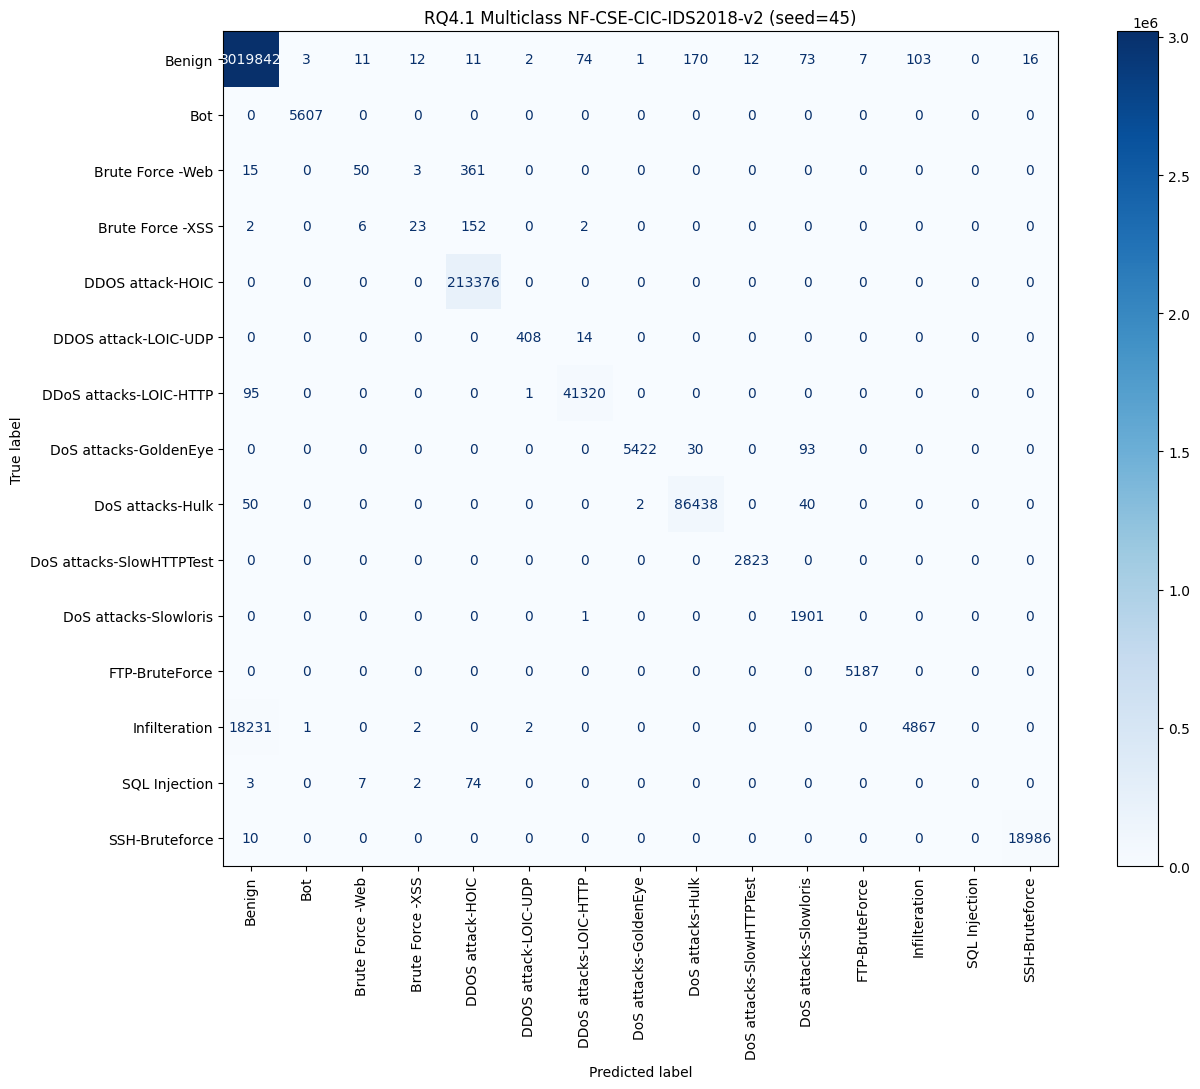

Saved outputs in: /kaggle/working/rq4_1_multiclass_ids_seed_45


In [10]:
# Vẽ confusion matrix sau khi đánh giá test.
cm = confusion_matrix(m['true'], m['pred'], labels=np.arange(len(CLASS_NAMES)))
fig, ax = plt.subplots(figsize=(14, 11))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
).plot(ax=ax, cmap='Blues', colorbar=True,
       xticks_rotation='vertical', values_format='d')
ax.set_title(f"RQ4.1 Multiclass {summary['dataset']} (seed={MODEL_SEED})")
plt.tight_layout()
figure_path = os.path.join(RUN_DIR, f'confusion_matrix_seed_{MODEL_SEED}.png')
plt.savefig(figure_path, dpi=150)
plt.show()
plt.close(fig)
print('Saved outputs in:', RUN_DIR)
